In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import poisson

df_N1 = pd.read_csv('/content/drive/MyDrive/Rugby_ProD2_Forecast/matchs_N-1.csv')
df_N2 = pd.read_csv('/content/drive/MyDrive/Rugby_ProD2_Forecast/matchs_N-2.csv')
df_vrai_classement = pd.read_csv('/content/drive/MyDrive/Rugby_ProD2_Forecast/classement_reel_N-1.csv')


In [29]:
# ==========================================
# 2. FONCTION DE CALCUL DES FORCES
# ==========================================
def calculer_forces(df):
    df_joues = df.dropna(subset=['home_score'])
    moyenne_generale = df_joues[['home_score', 'away_score']].mean().mean()

    stats_dom = df_joues.groupby('equipe_domicile').agg(
        marques_dom=('home_score', 'mean'), encaisses_dom=('away_score', 'mean')
    ).reset_index()

    stats_ext = df_joues.groupby('equipe_exterieur').agg(
        marques_ext=('away_score', 'mean'), encaisses_ext=('home_score', 'mean')
    ).reset_index()

    stats = pd.merge(stats_dom, stats_ext, left_on='equipe_domicile', right_on='equipe_exterieur', how='outer')
    stats['Equipe'] = stats['equipe_domicile'].fillna(stats['equipe_exterieur'])
    stats = stats.drop(columns=['equipe_domicile', 'equipe_exterieur'])

    stats['Attaque'] = ((stats['marques_dom'] + stats['marques_ext']) / 2).fillna(moyenne_generale)
    stats['Defense'] = ((stats['encaisses_dom'] + stats['encaisses_ext']) / 2).fillna(moyenne_generale)

    return stats, moyenne_generale

In [24]:
# ==========================================
# 3. APPRENTISSAGE ET TEST
# ==========================================
stats_N2, moyenne_N2 = calculer_forces(df_N2)

df_N1_debut = df_N1[df_N1['round'] <= 15].copy()
df_N1_reste = df_N1[df_N1['round'] > 15].copy()

stats_N1_debut, _ = calculer_forces(df_N1_debut)

# Fusion des forces
forces_finales = pd.merge(stats_N1_debut, stats_N2, on='Equipe', how='left', suffixes=('_actuel', '_N2'))
forces_finales['Attaque_N2'] = forces_finales['Attaque_N2'].fillna(moyenne_N2)
forces_finales['Defense_N2'] = forces_finales['Defense_N2'].fillna(moyenne_N2)

forces_finales['Attaque_Finale'] = (forces_finales['Attaque_actuel'] * 1.0 + forces_finales['Attaque_N2'] * 0.4) / 1.4
forces_finales['Defense_Finale'] = (forces_finales['Defense_actuel'] * 1.0 + forces_finales['Defense_N2'] * 0.4) / 1.4

# Normalisation
moyenne_attaques = forces_finales['Attaque_Finale'].mean()
moyenne_defenses = forces_finales['Defense_Finale'].mean()
forces_finales['Attaque_Finale'] = forces_finales['Attaque_Finale'] * (moyenne_N2 / moyenne_attaques)
forces_finales['Defense_Finale'] = forces_finales['Defense_Finale'] * (moyenne_N2 / moyenne_defenses)


In [ ]:
# ==========================================
# 4. MONTE-CARLO
# ==========================================
forces_dict = {}
for _, row in forces_finales.iterrows():
    attaque = max(row['Attaque_Finale'], 0.1) if not pd.isna(row['Attaque_Finale']) else 15.0
    defense = max(row['Defense_Finale'], 0.1) if not pd.isna(row['Defense_Finale']) else 15.0
    forces_dict[row['Equipe']] = {'attaque': attaque, 'defense': defense}

nombre_simulations = 1000
equipes = list(forces_dict.keys())
matchs_infos = []
equipe_index = {equipe: i for i, equipe in enumerate(equipes)}

for _, row in df_N1_reste.dropna(subset=['home_score']).iterrows():
    dom = row['equipe_domicile']
    ext = row['equipe_exterieur']
    if dom in forces_dict and ext in forces_dict:
        lambda_dom = (forces_dict[dom]['attaque'] * forces_dict[ext]['defense']) / moyenne_N2
        lambda_ext = (forces_dict[ext]['attaque'] * forces_dict[dom]['defense']) / moyenne_N2
        lambda_dom = min(max(lambda_dom, 0.1), 50)
        lambda_ext = min(max(lambda_ext, 0.1), 50)
        matchs_infos.append((equipe_index[dom], equipe_index[ext], lambda_dom, lambda_ext))

resultats = np.zeros((nombre_simulations, len(equipes)))
for sim in range(nombre_simulations):
    points_saison = np.zeros(len(equipes))
    for idx_dom, idx_ext, lambda_dom, lambda_ext in matchs_infos:
        score_dom = poisson.rvs(lambda_dom)
        score_ext = poisson.rvs(lambda_ext)
        if score_dom > score_ext: points_saison[idx_dom] += 4
        elif score_dom < score_ext: points_saison[idx_ext] += 4
        else:
            points_saison[idx_dom] += 2
            points_saison[idx_ext] += 2
        if abs(score_dom - score_ext) <= 5 and score_dom != score_ext:
            if score_dom < score_ext: points_saison[idx_dom] += 1
            else: points_saison[idx_ext] += 1
    resultats[sim] = points_saison



In [25]:
# ==========================================
# 5. COMPARAISON
# ==========================================
# Points déjà acquis sur les 15 journées
dom_pts = df_N1_debut.groupby('equipe_domicile')['pts_domicile'].sum().reset_index()
dom_pts.columns = ['Equipe', 'Points']
ext_pts = df_N1_debut.groupby('equipe_exterieur')['pts_exterieur'].sum().reset_index()
ext_pts.columns = ['Equipe', 'Points']
points_deja_acquis = pd.concat([dom_pts, ext_pts]).groupby('Equipe')['Points'].sum()

moyennes_points = np.mean(resultats, axis=0) + points_deja_acquis.reindex(equipes).fillna(0).values

df_prediction = pd.DataFrame({'Equipe': equipes, 'Points_Predits': moyennes_points})
df_prediction = df_prediction.sort_values(by='Points_Predits', ascending=False).reset_index(drop=True)
df_prediction['Rang_Predit'] = df_prediction.index + 1

df_comparaison = pd.merge(df_prediction, df_vrai_classement[['Equipe', 'Rang_Reel']], on='Equipe', how='left')

print("COMPARAISON : PRÉDICTION (après 15 journées) vs RÉALITÉ (fin de saison N-1) :")
display(df_comparaison[['Rang_Predit', 'Equipe', 'Points_Predits', 'Rang_Reel']])

COMPARAISON : PRÉDICTION (après 15 journées) vs RÉALITÉ (fin de saison N-1) :


,Rang_Predit,Equipe,Points_Predits,Rang_Reel
0,1,Vannes,89.611,1
1,2,Colomiers,81.807,2
2,3,Provence,77.271,3
3,4,Valence-Romans,75.983,4
4,5,Oyonnax,66.662,6
5,6,Brive,61.653,5
6,7,Grenoble,59.317,11
7,8,Agen,55.960,7
8,9,Aurillac,54.500,9
9,10,Nevers,53.767,15


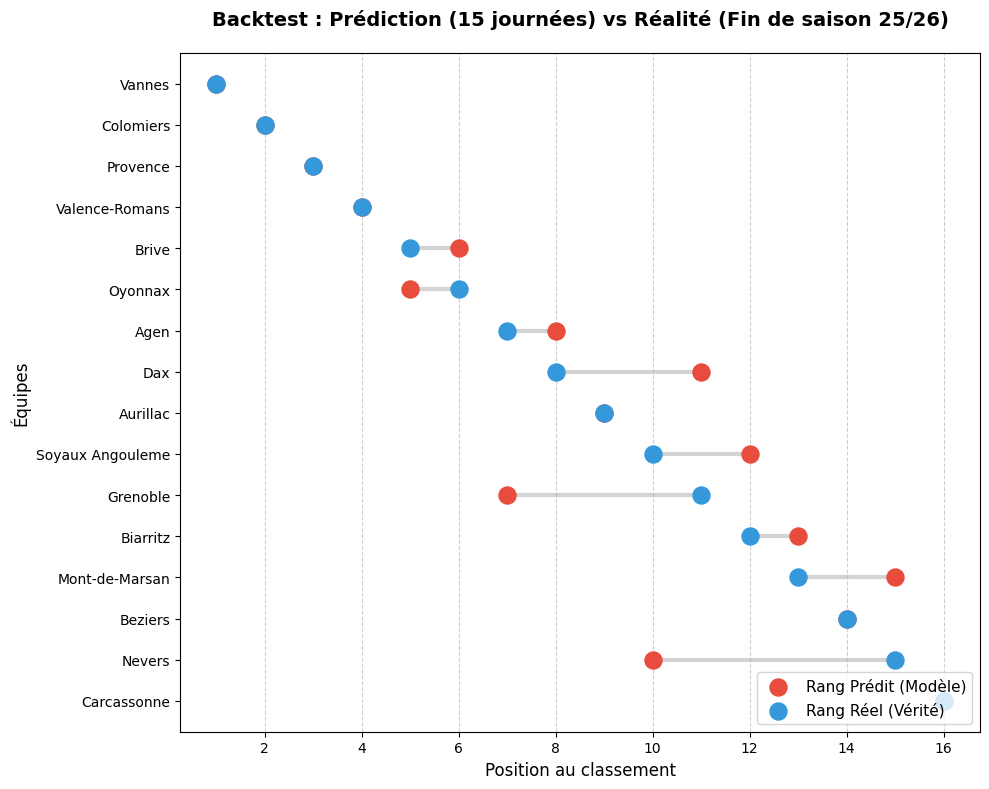

In [26]:
# ==========================================
# 1. PRÉPARATION DES DONNÉES POUR LE GRAPHIQUE
# ==========================================
df_plot = df_comparaison.copy()
df_plot['Rang_Predit'] = pd.to_numeric(df_plot['Rang_Predit'])
df_plot['Rang_Reel'] = pd.to_numeric(df_plot['Rang_Reel'])

df_plot = df_plot.sort_values(by='Rang_Reel', ascending=True).reset_index(drop=True)

# ==========================================
# 2. CRÉATION DU DOT PLOT
# ==========================================
fig, ax = plt.subplots(figsize=(10, 8))


for i, row in df_plot.iterrows():
    # Ligne de connexion
    ax.plot([row['Rang_Predit'], row['Rang_Reel']], [i, i],
            color='lightgray', linestyle='-', linewidth=3, zorder=1)

    # Point du rang PREDIT (Rouge)
    ax.scatter(row['Rang_Predit'], i, color='#e74c3c', s=150, zorder=3,
               label='Rang Prédit (Modèle)' if i == 0 else "")

    # Point du rang REEL (Bleu)
    ax.scatter(row['Rang_Reel'], i, color='#3498db', s=150, zorder=3,
               label='Rang Réel (Vérité)' if i == 0 else "")

# ==========================================
# 3. MISE EN FORME
# ==========================================

ax.set_yticks(range(len(df_plot)))
ax.set_yticklabels(df_plot['Equipe'])

ax.invert_yaxis()

ax.set_title("Backtest : Prédiction (15 journées) vs Réalité (Fin de saison 25/26)",
             fontsize=14, fontweight='bold', pad=20)
ax.set_xlabel("Position au classement", fontsize=12)
ax.set_ylabel("Équipes", fontsize=12)

ax.grid(axis='x', linestyle='--', alpha=0.6)

handles, labels = ax.get_legend_handles_labels()
by_label = dict(zip(labels, handles))
ax.legend(by_label.values(), by_label.keys(), loc='lower right', fontsize=11)

plt.tight_layout()
plt.show()